# ExitGuard — synthetic NIR dataset: check, train, evaluate, export

Runs the whole experiment on the Blender dataset (`images/` + `labels/`, each with `train/ val/ test/`):

| Part | What it does |
|---|---|
| 1 | Setup, settings, load the dataset |
| 2 | **Dataset checks** — counts, label sanity, **scene leakage between splits**, boxes on possibly invisible people |
| 3 | **Zero-shot baseline** — COCO-pretrained YOLO with no training |
| 4 | **Fine-tune** YOLO26n (and YOLOv8n) |
| 5 | **Evaluate** — Precision / Recall / mAP50 / mAP50-95 + safety metrics (missed occupied, empty-car false alarms, count), threshold picked on **val**, reported on **test** |
| 6 | **Export** static ONNX for the Pi kit (`07_live.py`) |

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Put the dataset (folder or zip) in Google Drive and set the paths in the settings cell. Then Runtime → Run all.
Everything that matters (results, trained weights, Pi models) is saved to `OUT_DIR` on Drive.

## 1. Setup

In [3]:
!pip -q install "ultralytics>=8.4" onnx onnxslim
import torch, ultralytics
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - set Runtime > T4 GPU")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("not on Colab - skipping Drive mount")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.220 | torch 2.14.1+cpu | GPU: NONE - set Runtime > T4 GPU
Mounted at /content/drive


### Settings — edit this cell

In [1]:
# ---- data ----
DATA_ZIP = "/content/drive/MyDrive/parking_detection_dataset/Training_dataset_v1.zip"   # zip on Drive, or None
DATA_DIR = "/content/drive/MyDrive/parking_detection_dataset/dataset"       # used when DATA_ZIP is None
OUT_DIR  = "/content/drive/MyDrive/parking_detection_dataset/colab_out"     # results + weights are saved here

# ---- split ----
RESPLIT     = "auto"   # "auto" = re-split by scene only if the same scene is in two splits; True / False
SPLIT_RATIO = (0.70, 0.15, 0.15)   # train / val / test, by scene (car_scenario_number)
HOLDOUT_CAR = None     # e.g. "ix35": all its scenes go to test only -> tests an unseen car (forces re-split)

# ---- training ----
MODELS   = ["yolo26n", "yolov8n"]   # COCO-pretrained starting points
EPOCHS   = 100
PATIENCE = 20
IMGSZ    = 640
BATCH    = 32          # lower to 16 if CUDA out of memory
CACHE    = False       # True = cache images in RAM (faster, needs RAM)

# ---- evaluation ----
RECALL_TARGET = 0.99   # threshold must find someone in >= 99% of occupied val images; best person F1 among those
SMALL_BOX     = 0.002  # boxes smaller than 0.2% of the image area are flagged for review
LOW_CONTRAST  = 6.0    # grey-level std inside a box below this = person maybe not visible

# ---- export for the Pi ----
EXPORT_SIZES = [320, 416, 640]
SEED = 0

In [4]:
import os, re, glob, shutil, random, zipfile, json, time
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

random.seed(SEED); np.random.seed(SEED)
OUT = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp"}
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# ---- get the data onto the local disk (much faster than reading from Drive) ----
LOCAL = Path("/content/ds_raw") if Path("/content").exists() else Path("ds_raw").resolve()
if LOCAL.exists():
    shutil.rmtree(LOCAL)
if DATA_ZIP:
    with zipfile.ZipFile(DATA_ZIP) as z:
        z.extractall(LOCAL)
else:
    shutil.copytree(DATA_DIR, LOCAL)

# find the folder that has images/ and labels/
cands = [p for p in LOCAL.rglob("images") if p.is_dir() and (p.parent / "labels").is_dir()]
if not cands:
    raise SystemExit("no folder with images/ and labels/ found in the dataset")
ROOT = cands[0].parent
SPLITS = {}
for s in ["train", "val", "valid", "test"]:
    if (ROOT / "images" / s).is_dir():
        SPLITS["val" if s == "valid" else s] = s
print("dataset root:", ROOT, "| splits:", SPLITS)

dataset root: /content/ds_raw/yolo_person | splits: {'train': 'train', 'val': 'val', 'test': 'test'}


## 2. Dataset checks

In [5]:
NAME_RE = re.compile(r"^(?P<car>.+?)_(?P<scen>[A-Za-z]+\d*)_(?P<scene>\d+)_f(?P<frame>\d+)_(?P<side>[LR])$")

def parse(stem):
    m = NAME_RE.match(stem)
    if not m:
        return dict(car="?", scen="?", scene="?", frame=-1, side="?", scene_key=stem)
    d = m.groupdict()
    d["frame"] = int(d["frame"])
    d["scene_key"] = f"{d['car']}_{d['scen']}_{d['scene']}"
    return d

def read_labels(p):
    rows, bad = [], []
    if p.exists():
        for ln in p.read_text().split("\n"):
            parts = ln.split()
            if not parts:
                continue
            try:
                c, x, y, w, h = int(float(parts[0])), *map(float, parts[1:5])
            except Exception:
                bad.append(ln); continue
            rows.append((c, x, y, w, h))
    return rows, bad

recs, boxes, problems = [], [], []
for split, folder in SPLITS.items():
    for ip in sorted((ROOT / "images" / folder).iterdir()):
        if ip.suffix.lower() not in IMG_EXT:
            continue
        lp = ROOT / "labels" / folder / (ip.stem + ".txt")
        labs, bad = read_labels(lp)
        W, H = Image.open(ip).size
        if not lp.exists():
            problems.append((ip.name, "no label file (treated as empty)"))
        for b in bad:
            problems.append((ip.name, f"unreadable line: {b!r}"))
        for c, x, y, w, h in labs:
            if c != 0:
                problems.append((ip.name, f"class {c} (expected 0)"))
            if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                problems.append((ip.name, f"box out of range {x,y,w,h}"))
            boxes.append(dict(split=split, img=str(ip), cls=c, x=x, y=y, w=w, h=h, area=w * h,
                              W=W, H=H, **parse(ip.stem)))
        recs.append(dict(split=split, img=str(ip), lbl=str(lp), W=W, H=H, n_gt=len(labs), **parse(ip.stem)))

df = pd.DataFrame(recs); bx = pd.DataFrame(boxes)
print(f"{len(df)} images, {len(bx)} person boxes, {(df.n_gt == 0).sum()} empty images")
print("image sizes:", df.groupby(["W", "H"]).size().to_dict())
unparsed = (df.car == "?").sum()
if unparsed:
    print(f"WARNING: {unparsed} file names don't match car_scenario_number_fN_L/R - leakage check uses the full name for those")
print(f"\nlabel problems: {len(problems)}")
for p in problems[:15]:
    print("  ", p)
display(pd.crosstab([df.car, df.scen], df.split, margins=True))
display(pd.crosstab(df.n_gt, df.split, margins=True).rename_axis("persons per image"))

8640 images, 15380 person boxes, 1026 empty images
image sizes: {(517, 218): 2916, (560, 239): 2922, (579, 250): 2802}

label problems: 0


split          test  train   val   All
car      scen                         
elantraN E0      30    234    36   300
         S0       6     12    12    30
         S1     234    576   150   960
         S2     474    984   168  1626
ix35     E0      60    198    42   300
         S0      12     18     0    30
         S1     162    708    90   960
         S2     390   1008   234  1632
palisade E0      60    180    60   300
         S0       6     12    12    30
         S1     168    630   126   924
         S2     456    912   180  1548
All            2058   5472  1110  8640

split,test,train,val,All
persons per image,,,,
0,180,678,168,1026
1,592,1959,369,2920
2,683,1509,339,2531
3,358,956,180,1494
4,137,253,39,429
5,108,117,15,240
All,2058,5472,1110,8640


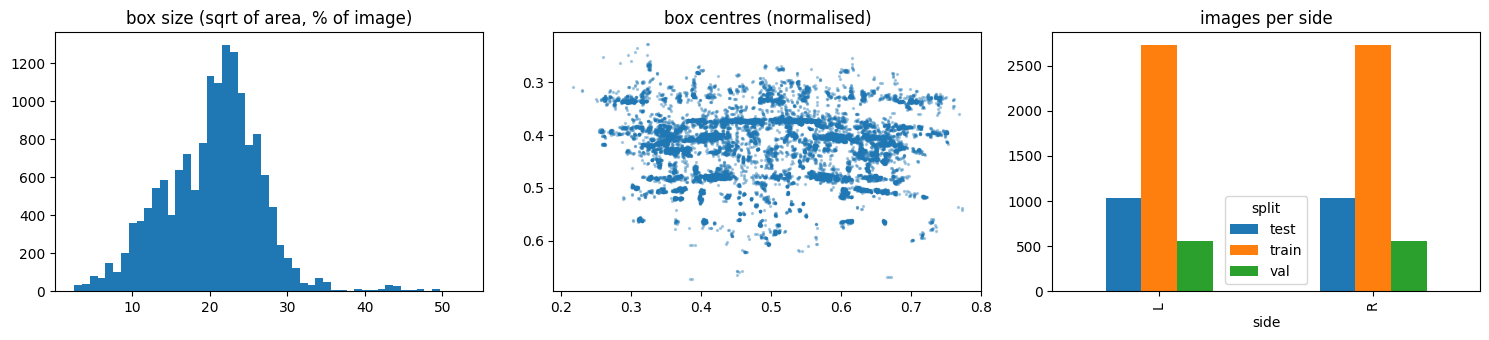

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(np.sqrt(bx.area) * 100, bins=50); ax[0].set_title("box size (sqrt of area, % of image)")
ax[1].scatter(bx.x, bx.y, s=2, alpha=.3); ax[1].invert_yaxis(); ax[1].set_title("box centres (normalised)")
df.groupby(["side", "split"]).size().unstack().plot.bar(ax=ax[2], title="images per side")
plt.tight_layout(); plt.show()

### 2a. Scene leakage between splits
Frames `f0, f1, f2` and sides `L/R` of one scene are near-duplicates. If one scene sits in two splits, val/test scores are inflated.

In [7]:
sk = df.groupby("scene_key").split.nunique()
leaky = sk[sk > 1].index
print(f"{df.scene_key.nunique()} scenes, {len(leaky)} appear in more than one split")
if len(leaky):
    display(df[df.scene_key.isin(leaky)].groupby(["scene_key", "split"]).size().unstack(fill_value=0).head(10))

need = HOLDOUT_CAR is not None or RESPLIT is True or (RESPLIT == "auto" and len(leaky) > 0)
DS = Path("/content/ds") if Path("/content").exists() else Path("ds").resolve()
if need:
    print("\n-> re-splitting by scene", f"(holding out car '{HOLDOUT_CAR}' for test)" if HOLDOUT_CAR else "")
    if DS.exists():
        shutil.rmtree(DS)
    rng = random.Random(SEED)
    new_split = {}
    pool = sorted(df.scene_key.unique())
    if HOLDOUT_CAR:
        held = [s for s in pool if s.split("_")[0] == HOLDOUT_CAR]
        if not held:
            raise SystemExit(f"no scenes for car {HOLDOUT_CAR}; cars: {sorted(df.car.unique())}")
        for s in held:
            new_split[s] = "test"
        pool = [s for s in pool if s not in held]
    # stratify by car+scenario so each split gets every kind of scene
    groups = defaultdict(list)
    for s in pool:
        groups["_".join(s.split("_")[:2])].append(s)
    tr, va, te = SPLIT_RATIO
    for g, ss in groups.items():
        rng.shuffle(ss)
        n = len(ss)
        n_te = 0 if HOLDOUT_CAR else max(1, round(n * te)) if n >= 3 else 0
        n_va = max(1, round(n * va)) if n - n_te >= 2 else 0
        for i, s in enumerate(ss):
            new_split[s] = "test" if i < n_te else "val" if i < n_te + n_va else "train"
    df["split"] = df.scene_key.map(new_split)
    for _, r in df.iterrows():
        for kind, src in (("images", r.img), ("labels", r.lbl)):
            dst = DS / kind / r.split / Path(src).name
            dst.parent.mkdir(parents=True, exist_ok=True)
            if Path(src).exists():
                os.symlink(src, dst)
    df["img"] = [str(DS / "images" / s / Path(p).name) for s, p in zip(df.split, df.img)]
    df["lbl"] = [str(DS / "labels" / s / Path(p).name) for s, p in zip(df.split, df.lbl)]
    bx["split"] = bx.scene_key.map(new_split)
    display(pd.crosstab([df.car, df.scen], df.split, margins=True))
else:
    DS = ROOT
    print("-> keeping the original split")

DATA_YAML = Path("/content/data.yaml" if Path("/content").exists() else "data.yaml").resolve()
val_folder = "val" if (DS / "images" / "val").is_dir() else "valid"
DATA_YAML.write_text(f"path: {DS}\ntrain: images/train\nval: images/{val_folder}\ntest: images/test\nnames:\n  0: person\n")
print(DATA_YAML.read_text())
df.to_csv(OUT / "dataset_index.csv", index=False)

1440 scenes, 0 appear in more than one split
-> keeping the original split
path: /content/ds_raw/yolo_person
train: images/train
val: images/val
test: images/test
names:
  0: person



### 2b. Look at the labels
Green = label box. Then the boxes flagged as **tiny** or **low-contrast** (maybe a person hidden behind the door/tint who should not be labelled). Check them by eye: if many flagged boxes show nobody, fix the Blender export (keep only boxes with enough visible pixels) before training.

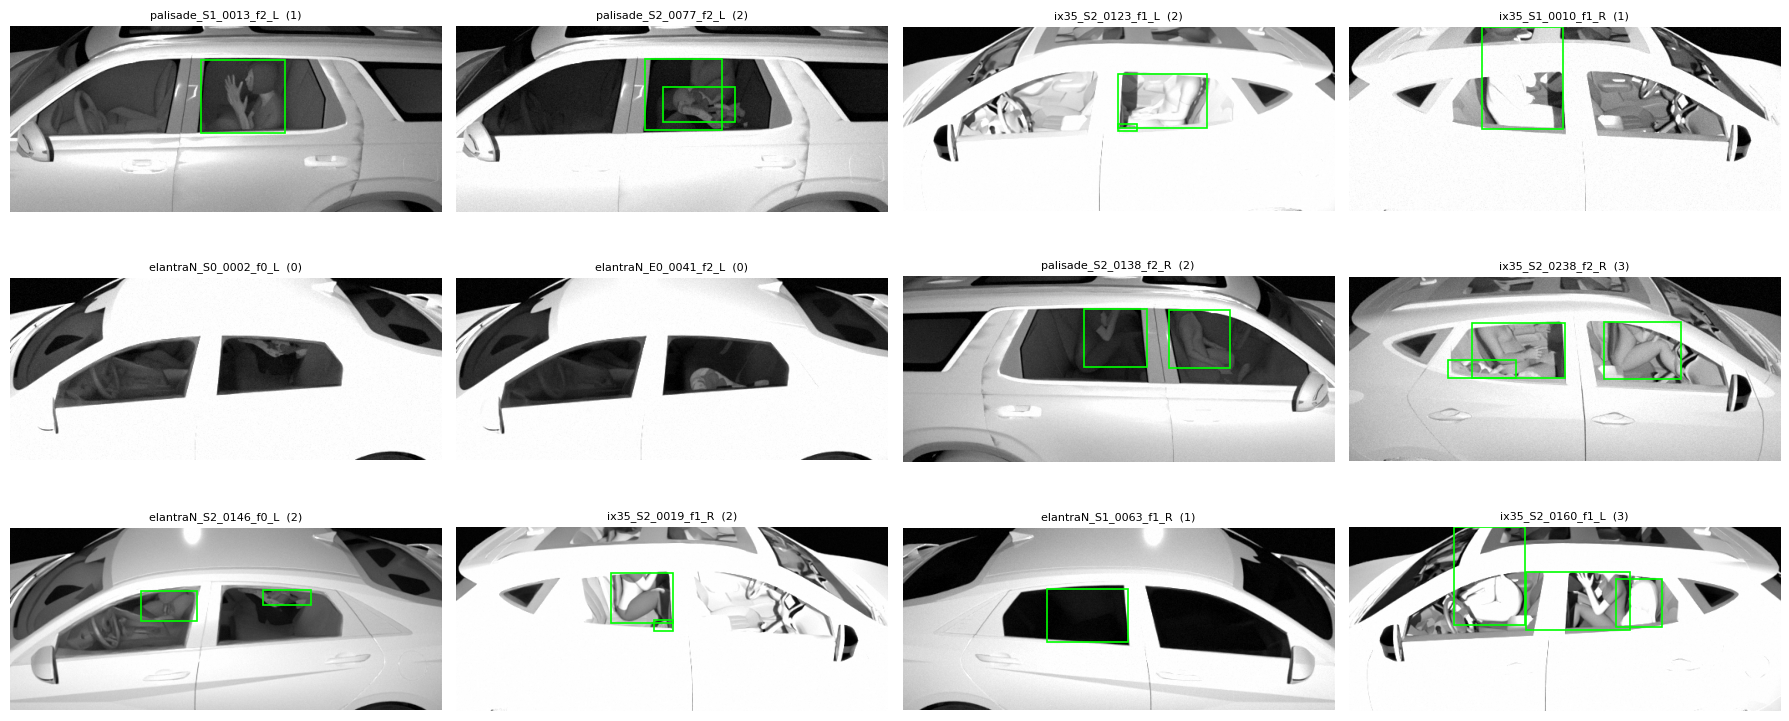

flagged 78 of 15380 boxes (0.5%): 67 tiny, 14 low-contrast


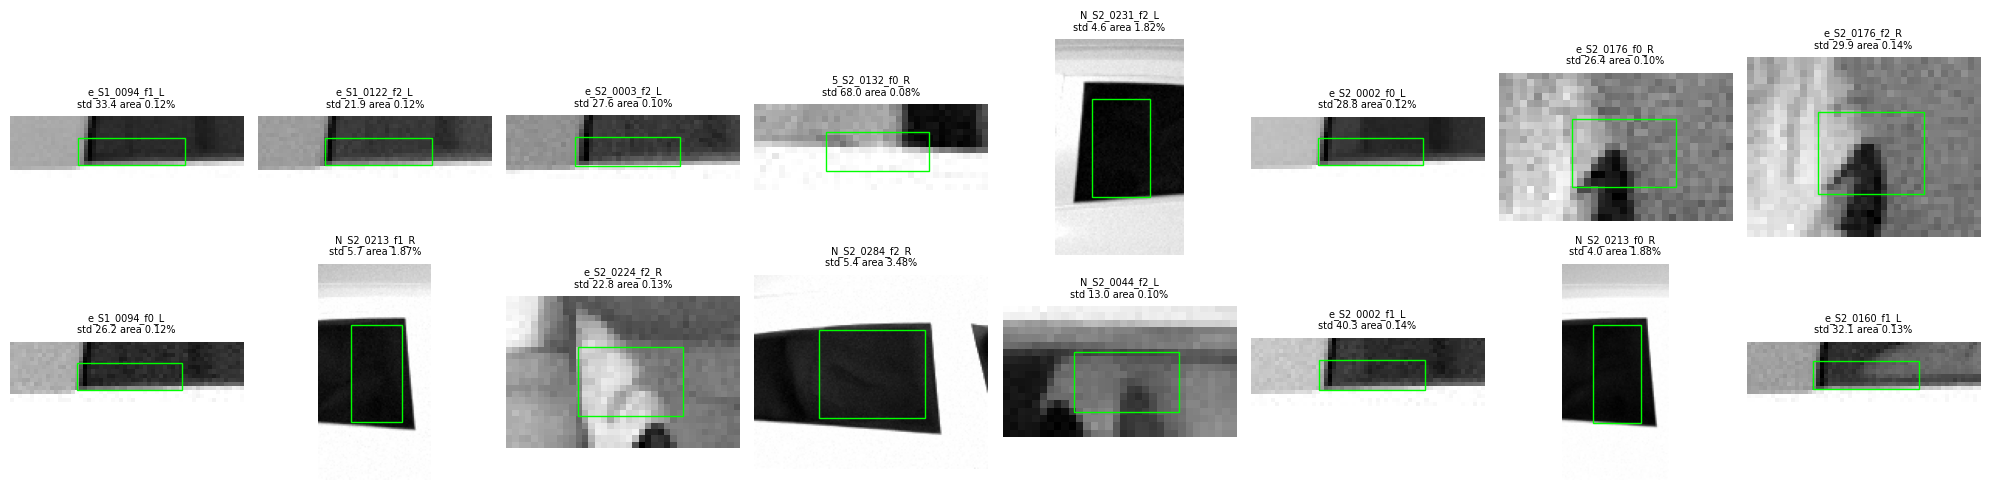

In [8]:
def draw(ax, path, gt=None, pred=None, title=""):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ax.imshow(im, cmap="gray"); ax.set_title(title, fontsize=8); ax.axis("off")
    H, W = im.shape
    for (x, y, w, h) in (gt if gt is not None else []):
        ax.add_patch(plt.Rectangle(((x - w / 2) * W, (y - h / 2) * H), w * W, h * H, fill=False, ec="lime", lw=1.2))
    for (x1, y1, x2, y2, c) in (pred if pred is not None else []):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1.2))
        ax.text(x1, y1, f"{c:.2f}", color="red", fontsize=6)

def gt_norm(path):
    return [(x, y, w, h) for _, x, y, w, h in read_labels(Path(path))[0]]

sample = df.sample(min(12, len(df)), random_state=SEED)
fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, (_, r) in zip(axs.flat, sample.iterrows()):
    draw(ax, r.img, gt_norm(r.lbl), title=f"{Path(r.img).stem}  ({r.n_gt})")
plt.tight_layout(); plt.show()

# contrast inside each box
bx["std"] = 0.0
for path, g in bx.groupby("img"):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    H, W = im.shape
    for i, r in g.iterrows():
        x1, y1 = int(max(0, (r.x - r.w / 2) * W)), int(max(0, (r.y - r.h / 2) * H))
        x2, y2 = int(min(W, (r.x + r.w / 2) * W)), int(min(H, (r.y + r.h / 2) * H))
        crop = im[y1:y2, x1:x2]
        bx.at[i, "std"] = float(crop.std()) if crop.size else 0.0
flag = bx[(bx.area < SMALL_BOX) | (bx["std"] < LOW_CONTRAST)]
print(f"flagged {len(flag)} of {len(bx)} boxes ({100 * len(flag) / max(len(bx), 1):.1f}%): "
      f"{(bx.area < SMALL_BOX).sum()} tiny, {(bx['std'] < LOW_CONTRAST).sum()} low-contrast")
if len(flag):
    show = flag.sample(min(16, len(flag)), random_state=SEED)
    fig, axs = plt.subplots(2, 8, figsize=(20, 5))
    for ax, r in zip(axs.flat, show.itertuples()):
        im = cv2.imread(r.img, cv2.IMREAD_GRAYSCALE); H, W = im.shape
        pw, ph = r.w * W * 0.6, r.h * H * 0.6
        x1, y1 = int(max(0, (r.x - r.w / 2) * W - pw)), int(max(0, (r.y - r.h / 2) * H - ph))
        x2, y2 = int(min(W, (r.x + r.w / 2) * W + pw)), int(min(H, (r.y + r.h / 2) * H + ph))
        ax.imshow(im[y1:y2, x1:x2], cmap="gray")
        ax.add_patch(plt.Rectangle(((r.x - r.w / 2) * W - x1, (r.y - r.h / 2) * H - y1), r.w * W, r.h * H,
                                   fill=False, ec="lime", lw=1))
        ax.set_title(f"{Path(r.img).stem[-14:]}\nstd {r.std:.1f} area {100 * r.area:.2f}%", fontsize=7); ax.axis("off")
    for ax in axs.flat[len(show):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()
bx.to_csv(OUT / "boxes_index.csv", index=False)

## 3–5. Evaluation helpers
Same matching as the Pi kit (`05_accuracy.py`): greedy by confidence, IoU ≥ 0.5 for P/R/AP50; mAP50-95 = mean AP over IoU 0.50…0.95.
**Threshold:** among thresholds where ≥ `RECALL_TARGET` of occupied val images get a detection, the one with the best person-level F1.
**Safety metrics** are per image: *presence recall* (occupied image → at least one detection), *empty false alarm* (empty image → any detection), count exact / MAE / undercount. **Scene-level** combines frames and sides like the real system (L only, R only, L **or** R).
The threshold is chosen on **val**, then applied unchanged to **test**.

In [9]:
def to_xyxy(path):
    W, H = Image.open(path).size
    g = np.array([[(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H]
                  for _, x, y, w, h in read_labels(Path(path.replace("/images/", "/labels/")).with_suffix(".txt"))[0]],
                 dtype=np.float32)
    return g.reshape(-1, 4)

def iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def match(d, g, thr):
    d = d[np.argsort(-d[:, 4])] if len(d) else d
    tp = np.zeros(len(d), bool); used = np.zeros(len(g), bool); m = iou(d[:, :4], g)
    for i in range(len(d)):
        cand = np.where(~used & (m[i] >= thr))[0] if len(g) else []
        if len(cand):
            j = cand[np.argmax(m[i, cand])]; used[j] = True; tp[i] = True
    return d[:, 4] if len(d) else np.zeros(0), tp

def ap(conf, tp, n_gt):
    if n_gt == 0 or len(conf) == 0:
        return np.nan
    o = np.argsort(-conf); tp = tp[o].astype(float)
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec = ctp / n_gt; prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[1, prec, 0]
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

def predict_split(model, split, coco=False, batch=32):
    paths = df[df.split == split].img.tolist()
    out = {}
    for i in range(0, len(paths), batch):
        res = model.predict(paths[i:i + batch], imgsz=IMGSZ, conf=0.001, iou=0.7, max_det=100,
                            classes=[0], device=DEVICE, verbose=False)
        for p, r in zip(paths[i:i + batch], res):
            b = r.boxes
            out[p] = (np.c_[b.xyxy.cpu().numpy(), b.conf.cpu().numpy()] if len(b) else np.zeros((0, 5)))
    gts = {p: to_xyxy(p) for p in paths}
    return out, gts

def box_metrics(preds, gts, conf):
    n_gt = sum(len(g) for g in gts.values()); tp = fp = 0
    for p, d in preds.items():
        c, t = match(d[d[:, 4] >= conf], gts[p], 0.5); tp += t.sum(); fp += (~t).sum()
    P = tp / max(tp + fp, 1); R = tp / max(n_gt, 1)
    aps = []
    for thr in np.arange(0.5, 0.951, 0.05):
        cs, ts = zip(*[match(d, gts[p], thr) for p, d in preds.items()]) if preds else ([], [])
        aps.append(ap(np.concatenate(cs), np.concatenate(ts), n_gt))
    return dict(precision=P, recall=R, f1=2 * P * R / max(P + R, 1e-9), ap50=aps[0], map50_95=np.nanmean(aps))

def image_metrics(preds, gts, conf, rows=None):
    occ = det_occ = emp = fa = exact = under = 0; err = []
    for p, d in preds.items():
        if rows is not None and p not in rows:
            continue
        n = int((d[:, 4] >= conf).sum()); g = len(gts[p])
        if g: occ += 1; det_occ += n > 0
        else: emp += 1; fa += n > 0
        exact += n == g; under += n < g; err.append(abs(n - g))
    N = max(len(err), 1)
    return dict(images=len(err), presence_recall=det_occ / occ if occ else np.nan,
                missed_occupied=occ - det_occ, empty_false_alarm=fa / emp if emp else np.nan,
                count_exact=exact / N, count_mae=float(np.mean(err)) if err else np.nan, undercount=under / N)

def scene_metrics(preds, gts, conf):
    sub = df[df.img.isin(preds.keys())]
    out = {}
    for mode in ["L", "R", "L|R"]:
        occ = hit = emp = fa = 0
        for sk, g in sub.groupby("scene_key"):
            occupied = g.n_gt.sum() > 0
            sides = ["L", "R"] if mode == "L|R" else [mode]
            gg = g[g.side.isin(sides)]
            if gg.empty:
                continue
            found = any((preds[p][:, 4] >= conf).any() for p in gg.img)
            if occupied: occ += 1; hit += found
            else: emp += 1; fa += found
        out[mode] = dict(scenes_occupied=occ, scene_presence_recall=hit / occ if occ else np.nan,
                         scenes_empty=emp, scene_false_alarm=fa / emp if emp else np.nan)
    return out

def pr_at(preds, gts, conf):
    n_gt = sum(len(g) for g in gts.values()); tp = fp = 0
    for p, d in preds.items():
        _, t = match(d[d[:, 4] >= conf], gts[p], 0.5); tp += t.sum(); fp += (~t).sum()
    P, R = tp / max(tp + fp, 1), tp / max(n_gt, 1)
    return dict(box_precision=P, box_recall=R, box_f1=2 * P * R / max(P + R, 1e-9))

def pick_conf(preds, gts, target=RECALL_TARGET):
    # safety first: keep thresholds where >= target of occupied images get a detection,
    # then take the one with the best person-level F1 (so counting stays good too)
    grid = np.round(np.arange(0.05, 0.91, 0.05), 2)
    t = pd.DataFrame([dict(conf=c, **image_metrics(preds, gts, c), **pr_at(preds, gts, c)) for c in grid])
    ok = t[t.presence_recall >= target] if t.presence_recall.notna().any() else t
    if ok.empty:
        print(f"  no threshold reaches presence recall {target} on val - using the lowest (0.05)")
        return 0.05, t
    return float(ok.loc[ok.box_f1.idxmax(), "conf"]), t

RESULTS = []

def evaluate(model, tag, coco=False):
    t0 = time.time()
    pv, gv = predict_split(model, "val", coco)
    conf, sweep = pick_conf(pv, gv)
    pt, gt = predict_split(model, "test", coco)
    bm = box_metrics(pt, gt, conf); im = image_metrics(pt, gt, conf); sm = scene_metrics(pt, gt, conf)
    row = dict(model=tag, conf=conf, **{k: round(float(v), 4) for k, v in bm.items()},
               **{k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in im.items()},
               **{f"scene_{m}_recall": round(v["scene_presence_recall"], 4) for m, v in sm.items()},
               **{f"scene_{m}_false_alarm": round(v["scene_false_alarm"], 4) for m, v in sm.items()})
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(OUT / "results_test.csv", index=False)
    print(f"[{tag}] conf {conf} (chosen on val: presence recall >= {RECALL_TARGET}, then best person F1)"
          f"  ({time.time() - t0:.0f}s)")
    if not any(len(g) == 0 for g in gt.values()):
        print("  NOTE: test split has no empty images - empty-car false alarms can't be measured")
    display(pd.DataFrame([row]).T.rename(columns={0: tag}))
    return pt, gt, conf, sweep

## 3. Zero-shot baseline (COCO-pretrained, no training)
COCO class 0 is also *person*, so the untrained model can be scored directly. This is the "before" number for the report.

In [10]:
ZERO = {}
for m in MODELS:
    ZERO[m] = evaluate(YOLO(f"{m}.pt"), f"{m} zero-shot", coco=True)

  no threshold reaches presence recall 0.99 on val - using the lowest (0.05)
[yolo26n zero-shot] conf 0.05 (chosen on val: presence recall >= 0.99, then best person F1)  (289s)


,yolo26n zero-shot
model,yolo26n zero-shot
conf,0.05
precision,0.4436
recall,0.3786
f1,0.4085
ap50,0.3396
map50_95,0.1406
images,2058
presence_recall,0.7093
missed_occupied,546


  no threshold reaches presence recall 0.99 on val - using the lowest (0.05)
[yolov8n zero-shot] conf 0.05 (chosen on val: presence recall >= 0.99, then best person F1)  (336s)


,yolov8n zero-shot
model,yolov8n zero-shot
conf,0.05
precision,0.4247
recall,0.2752
f1,0.334
ap50,0.2541
map50_95,0.0982
images,2058
presence_recall,0.6858
missed_occupied,590


## 4. Fine-tune
Grayscale NIR → colour augmentation off (`hsv_h=0, hsv_s=0`), brightness on. Left/right mirror on (a mirrored L view looks like an R view). Empty images (no label lines) stay in as negatives.
Runs are saved to Drive (`OUT_DIR/runs/<model>`), so a disconnect doesn't lose finished epochs: re-run this cell with `RESUME = True` to continue.

In [ ]:
RESUME = False
BEST = {}
for m in MODELS:
    run_dir = OUT / "runs" / m
    last = run_dir / "weights" / "last.pt"
    if RESUME and last.exists():
        model = YOLO(str(last)); model.train(resume=True)
    else:
        model = YOLO(f"{m}.pt")
        model.train(data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, patience=PATIENCE, batch=BATCH,
                    device=DEVICE, cache=CACHE, seed=SEED, workers=2,
                    hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, fliplr=0.5, mosaic=1.0, close_mosaic=10,
                    project=str(OUT / "runs"), name=m, exist_ok=True, plots=True)
    BEST[m] = run_dir / "weights" / "best.pt"
    print(m, "->", BEST[m])

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, 

In [11]:
BEST = {m: OUT / "runs" / m / "weights" / "best.pt" for m in MODELS}
for m, p in BEST.items():
    assert p.exists(), f"missing {p}"
    print(m, "->", p)

yolo26n -> /content/drive/MyDrive/parking_detection_dataset/colab_out/runs/yolo26n/weights/best.pt
yolov8n -> /content/drive/MyDrive/parking_detection_dataset/colab_out/runs/yolov8n/weights/best.pt


## 5. Evaluate the fine-tuned models

In [12]:
FT, UVAL = {}, []
for m in MODELS:
    model = YOLO(str(BEST[m]))
    r = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, device=DEVICE, plots=False, verbose=False)
    UVAL.append(dict(model=m, P=r.box.mp, R=r.box.mr, mAP50=r.box.map50, mAP50_95=r.box.map))
    FT[m] = evaluate(model, f"{m} fine-tuned")
print("Ultralytics val on test (its own conf/threshold conventions):")
display(pd.DataFrame(UVAL).round(4))

Ultralytics 8.4.220 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1855.5±820.9 MB/s, size: 88.8 KB)
val: Scanning /content/ds_raw/yolo_person/labels/test... 2058 images, 180 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2058/2058 1.4Kit/s 1.5s
val: New cache created: /content/ds_raw/yolo_person/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 129/129 1.3s/it 2:46
                   all       2058       4120      0.961      0.879      0.931      0.758
Speed: 1.5ms preprocess, 73.1ms inference, 0.0ms loss, 0.3ms postprocess per image
  no threshold reaches presence recall 0.99 on val - using the lowest (0.05)
[yolo26n fine-tuned] conf 0.05 (chosen on val: presence recall >= 0.99, then best person F1)  (265s)


,yolo26n fine-tuned
model,yolo26n fine-tuned
conf,0.05
precision,0.8105
recall,0.9269
f1,0.8648
ap50,0.9372
map50_95,0.7592
images,2058
presence_recall,0.9989
missed_occupied,2


Ultralytics 8.4.220 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1647.5±477.2 MB/s, size: 77.1 KB)
val: Scanning /content/ds_raw/yolo_person/labels/test.cache... 2058 images, 180 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2058/2058 539.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 129/129 1.6s/it 3:26
                   all       2058       4120      0.954      0.881      0.937      0.761
Speed: 2.2ms preprocess, 92.0ms inference, 0.0ms loss, 0.3ms postprocess per image
[yolov8n fine-tuned] conf 0.05 (chosen on val: presence recall >= 0.99, then best person F1)  (310s)


,yolov8n fine-tuned
model,yolov8n fine-tuned
conf,0.05
precision,0.7972
recall,0.935
f1,0.8606
ap50,0.9437
map50_95,0.7627
images,2058
presence_recall,0.9995
missed_occupied,1


Ultralytics val on test (its own conf/threshold conventions):


,model,P,R,mAP50,mAP50_95
0,yolo26n,0.9605,0.8791,0.9307,0.7578
1,yolov8n,0.9538,0.8809,0.9367,0.7609


### Summary — zero-shot vs fine-tuned (test split)

In [13]:
res = pd.DataFrame(RESULTS)
cols = ["model", "conf", "precision", "recall", "ap50", "map50_95", "presence_recall", "missed_occupied",
        "empty_false_alarm", "count_exact", "count_mae", "undercount",
        "scene_L_recall", "scene_R_recall", "scene_L|R_recall", "scene_L|R_false_alarm"]
display(res[[c for c in cols if c in res]])
res.to_csv(OUT / "results_test.csv", index=False)

,model,conf,precision,recall,ap50,map50_95,presence_recall,missed_occupied,empty_false_alarm,count_exact,count_mae,undercount,scene_L_recall,scene_R_recall,scene_L|R_recall,scene_L|R_false_alarm
0,yolo26n zero-shot,0.05,0.4436,0.3786,0.3396,0.1406,0.7093,546,0.5167,0.2512,1.2668,0.4660,0.8344,0.7643,0.8822,0.8276
1,yolov8n zero-shot,0.05,0.4247,0.2752,0.2541,0.0982,0.6858,590,0.2833,0.2643,1.2021,0.5598,0.7962,0.7994,0.9045,0.6207
2,yolo26n fine-tuned,0.05,0.8105,0.9269,0.9372,0.7592,0.9989,2,0.1500,0.7002,0.4130,0.0607,0.9968,1.0000,1.0000,0.3103
3,yolov8n fine-tuned,0.05,0.7972,0.9350,0.9437,0.7627,0.9995,1,0.1000,0.6953,0.4431,0.0481,0.9968,0.9968,1.0000,0.2069


### Where does it fail? (best fine-tuned model)
By car / scenario / side, the confidence-threshold trade-off on val, and the occupied test images it missed (green = label, red = prediction).

best model: yolov8n | conf 0.05


,car,scen,side,images,presence_recall,missed_occupied,empty_false_alarm,count_exact,count_mae,undercount
0,elantraN,E0,L,15,NaN,0,0.000,1.000,0.000,0.000
1,elantraN,E0,R,15,NaN,0,0.000,1.000,0.000,0.000
2,elantraN,S0,L,3,NaN,0,1.000,0.000,1.000,0.000
3,elantraN,S0,R,3,NaN,0,1.000,0.000,1.000,0.000
4,elantraN,S1,L,117,0.991,1,NaN,0.838,0.179,0.009
5,elantraN,S1,R,117,1.000,0,NaN,0.769,0.299,0.000
6,elantraN,S2,L,237,1.000,0,NaN,0.553,0.654,0.084
7,elantraN,S2,R,237,1.000,0,NaN,0.473,1.000,0.063
8,ix35,E0,L,30,NaN,0,0.000,1.000,0.000,0.000
9,ix35,E0,R,30,NaN,0,0.000,1.000,0.000,0.000


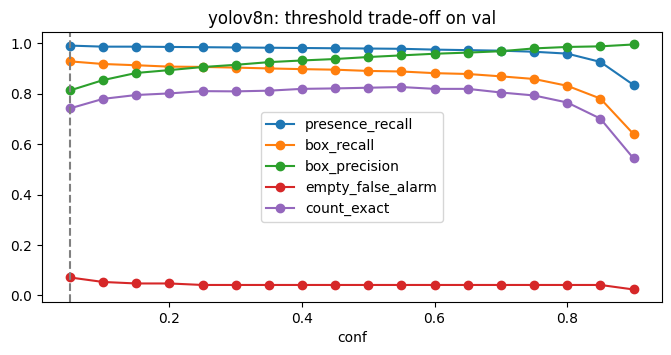

missed occupied images: 1 | empty images with a false alarm: 18


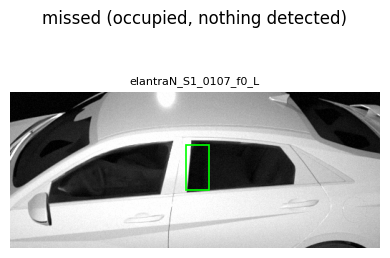

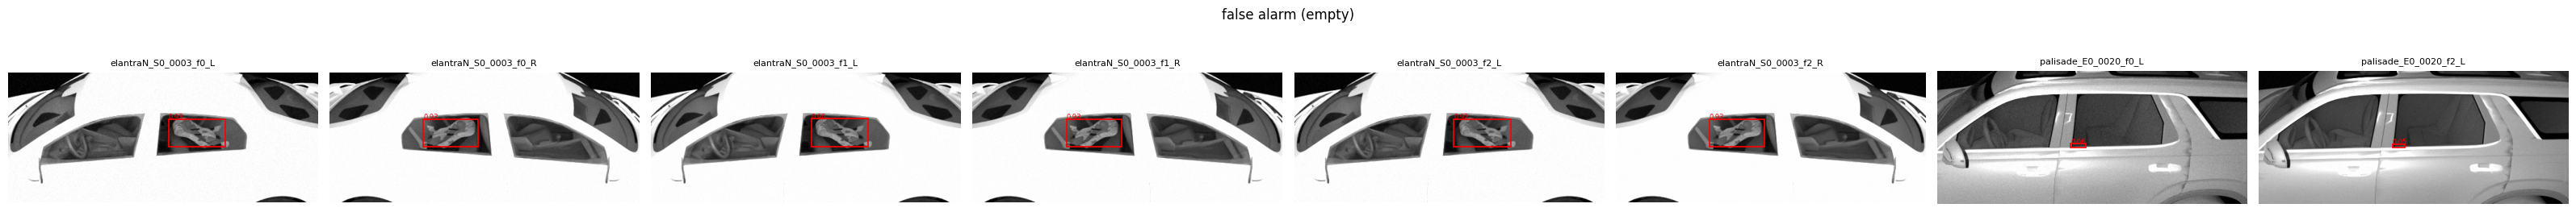

In [14]:
best_m = max(FT, key=lambda m: (res[res.model == f"{m} fine-tuned"].presence_recall.iat[0],
                                 res[res.model == f"{m} fine-tuned"].map50_95.iat[0]))
pt, gt, conf, sweep = FT[best_m]
print("best model:", best_m, "| conf", conf)

rows = []
sub = df[df.split == "test"]
for keys, g in sub.groupby(["car", "scen", "side"]):
    imset = set(g.img)
    rows.append(dict(car=keys[0], scen=keys[1], side=keys[2], **image_metrics(pt, gt, conf, rows=imset)))
display(pd.DataFrame(rows).round(3))

ax = sweep.plot(x="conf", y=["presence_recall", "box_recall", "box_precision", "empty_false_alarm", "count_exact"], marker="o",
                figsize=(8, 3.5), title=f"{best_m}: threshold trade-off on val")
ax.axvline(conf, ls="--", c="grey"); plt.show()

missed = [p for p in pt if len(gt[p]) and not (pt[p][:, 4] >= conf).any()]
fa = [p for p in pt if not len(gt[p]) and (pt[p][:, 4] >= conf).any()]
print(f"missed occupied images: {len(missed)} | empty images with a false alarm: {len(fa)}")
for title, lst in (("missed (occupied, nothing detected)", missed), ("false alarm (empty)", fa)):
    if not lst:
        continue
    show = lst[:8]
    fig, axs = plt.subplots(1, len(show), figsize=(4 * len(show), 3), squeeze=False)
    for ax, p in zip(axs[0], show):
        d = pt[p][pt[p][:, 4] >= min(conf, 0.1)]
        draw(ax, p, gt_norm(df.loc[df.img == p, "lbl"].iat[0]), d, Path(p).stem)
    fig.suptitle(title); plt.tight_layout(); plt.show()

## 6. Export for the Pi
Static ONNX (fixed input, batch 1) at each size, named for the Pi kit: `models/<name>_<size>.onnx`.
Copy the files into `~/exitguard_camtest/models/` on the Pi and run e.g.
`python 07_live.py --model yolo26n_eg --format onnx --imgsz 416 --view --no-cooldown`.

In [15]:
PI = OUT / "pi_models"; PI.mkdir(exist_ok=True)
for m in MODELS:
    name = f"{m}_eg"
    shutil.copy(BEST[m], PI / f"{name}.pt")
    for s in EXPORT_SIZES:
        variants = [("", {})] + ([("_e2e", {"nms": False})] if m.startswith("yolo26") else [])
        for suf, kw in variants:
            f = Path(YOLO(str(BEST[m])).export(format="onnx", imgsz=s, dynamic=False, simplify=True,
                                                verbose=False, **kw))
            dst = PI / f"{name}_{s}{suf}.onnx"
            shutil.move(str(f), dst)
            print(f"{dst.name:28s} {dst.stat().st_size / 1e6:6.2f} MB")
zip_path = shutil.make_archive(str(OUT / "pi_models"), "zip", PI)
print("\nzip for the Pi:", zip_path)
json.dump(dict(conf_threshold={m: FT[m][2] for m in FT}, imgsz=IMGSZ, recall_target=RECALL_TARGET),
          open(OUT / "deploy_settings.json", "w"), indent=2)
print("chosen thresholds saved to", OUT / "deploy_settings.json")

Ultralytics 8.4.220 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 1.3 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/parking_detection_dataset/colab_out/runs/yolo26n/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 5, 2100) (5.2 MB)
requirements: Ultralytics requirement ['onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 5 packages in 327ms
Prepared 1 package in 745ms
Installed 1 package in 11ms
 + onnxruntime==1.32.0

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 4.7s, saved as 

### Notes
- **Numbers on synthetic test data are an upper bound.** The real test is your own NoIR recordings: keep them out of training and score them with the same helpers (put them in a folder with `images/test` + `labels/test` and point `DATA_DIR` at it with `RESPLIT=False`, skip training, load `BEST`).
- **Unseen car:** set `HOLDOUT_CAR = "ix35"` (or another car) and run again — this shows whether the model generalises to a car it never saw.
- **Accuracy is the same on the Pi** for these FP32 ONNX files; only speed must be measured there (`07_live.py`).